In [1]:
from pyspark.sql import SparkSession
import numpy as np

import pyspark
from pyspark import SparkConf, SparkContext
from pyspark.sql.types import StructType, StructField, IntegerType, StringType, DateType, DoubleType
from pyspark.sql import functions as F
from pyspark.sql import DataFrame
from pyspark.sql import types as spark_types

from rouge_score import rouge_scorer
from pyspark.sql import Row

SEED = 42
# If False, load the cleaned dataframe from root directory
# All previous steps can be skipped; simply start running the process directly from the “Data Cleaning” cell.
REBUILD_CLEANING = False

ss  = SparkSession.builder \
                            .master("local[1]")\
                            .appName("SparkByExamples.com")\
                            .getOrCreate()
sc = ss.sparkContext

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/27 11:07:53 WARN Utils: Your hostname, NineQueendeMacBook-Air.local, resolves to a loopback address: 127.0.0.1; using 172.20.139.247 instead (on interface en0)
26/10/27 11:07:53 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/27 11:07:53 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
schema = StructType([
    StructField("uniqueID", IntegerType()),
    StructField("drugName", StringType()),
    StructField("condition", StringType()),
    StructField("review", StringType()),
    StructField("rating", IntegerType()),
    StructField("date", DateType()),
    StructField("usefulCount", IntegerType()),
])

df_raw = ss.read.csv(
    "drugsComTrain_raw.csv",
    schema = schema,
    header=True,
    multiLine=True,
    escape='"',
    dateFormat = "d-MMM-yy",
    locale = "en-US"
)
df_raw.show(truncate= 80)
print("rows:", df_raw.count())

+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                          drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|                         Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|                        Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                            Lybrel|               Birth Cont

### Exploratory Data Analysis (EDA)
Begin by trying to comprehend what your dataset conveys.
- What type of data are you currently exploring?
- What is the granularity of the data?
- What does the distribution of the data look like? Are there any outliers? Are there any
- missing or invalid entries?
- Is there any correlation between the variables you are interested in exploring?
- How would you cleanly and accurately visualize the relationship among variables?

In [3]:
class EDA:
    def __init__(self, df: DataFrame) -> None:
        self.df = df

    def dataframe_overview(self):
        df = self.df
        print("="*32)
        print("DataFrame overview")
        print("="*32)

        # We can see HTML entities such as "&#039;".
        df.show(5,truncate=80)
        print("Schema:")
        df.printSchema()

    def granularity(self):
        df = self.df
        print("="*32)
        print("DataFrame granularity")
        print("="*32)

        print("Total row count:", end = " ")
        print(df.count())
        print("`drugName`:")
        df.select("drugName").distinct().show(truncate=50)
        print("`drugName` count:", end = " ")
        print(df.select("drugname").distinct().count())
        print("`condition`:")
        df.select("condition").distinct().show(truncate=50)
        print("`condition` count:",end=" ")
        # We can see "55</span> users found this comment helpful." shown below,
        # which is an abnormal `condition` value.
        print(df.select("condition").distinct().count())
        print("`uniqueID` is unique" if df.count() == df.select("uniqueID").distinct().count()
            else  "`uniqueID` is not unique")
        
        df_review = df.groupBy("review").agg(
                        F.count("*").alias("n"),
                        F.countDistinct("rating").alias("rating_n"),
                    ).filter((F.col("n") > 1))
        review_count = df_review.count()
        if review_count == 0:
            print("`review` values are unique")
        else:
            print(f"`review` is not unique: {review_count} groups contain duplicate `review` values")
            df_review.show(5,truncate=80)
            print(
                "But only {} groups of `review` have different `rating` values".format(
                    df_review.filter(F.col("rating_n") > 1).count()
                )
            )
        
    def distribution_inspect(self):
        df = self.df
        print("="*32)
        print("Data Distribution")
        print("="*32)
        
        print("`rating` is in the range [0, 10]" if df.filter((F.col("rating") >= 0) & (F.col("rating") <= 10)).count() == df.count()
            else "`rating` is not in the range [0, 10]")
        
        print("`rating` record count:")
        rating_count = df.groupBy("rating").count().orderBy("rating")
        rating_count.show()
        df.agg(
            F.variance("rating").alias("variance"),
            F.stddev("rating").alias("stddev"),
            F.skewness("rating").alias("skewness"),
        ).show()
        rating_count.toPandas().plot.bar(x="rating", y="count", legend=False)

        print("`usefulCount`:")
        df.select("usefulCount").summary("min", "25%", "50%", "75%", "max").show()
        df.agg(
            F.variance("usefulCount").alias("variance"),
            F.stddev("usefulCount").alias("stddev"),
            F.skewness("usefulCount").alias("skewness"),
        ).show()
        useful_ax = df.select("usefulCount").toPandas().plot.hist(bins=40, range=(0, 200), legend=False)
        useful_ax.set_xlabel("usefulCount")

        print("`review` length:")
        length = F.length(F.col("review"))
        df.select(length.alias("review_length")).summary("min", "25%", "50%", "75%", "max").show()
        df.agg(
            F.variance(length).alias("variance"),
            F.stddev(length).alias("stddev"),
            F.skewness(length).alias("skewness"),
        ).show()
        length_ax = df.select(length.alias("review_length")).toPandas().plot.hist(bins=40, range=(0, 1500), legend=False)
        length_ax.set_xlabel("review_length")
        
        for col in df.columns:
            print(f"`{col}` has {df.filter(F.col(col).isNull()).count()} null records")

    def correlation(self):
        df = self.df
        print("="*32)
        print("Data Field Correlation")
        print("="*32)
        numeric = df.select(
            "rating",
            "usefulCount",
            F.unix_date("date").alias("date"),
        )
        columns = numeric.columns
        numeric.agg(
            *(
                F.corr(columns[i], columns[j]).alias(f"{columns[i]}_{columns[j]}")
                for i in range(len(columns))
                for j in range(i + 1, len(columns))
            )
        ).show()
        

EDA_df = EDA(df_raw)
EDA_df.dataframe_overview()

DataFrame overview
+--------+------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|               Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|              Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                  Lybrel|               Birth Control|"I used to take another oral contrace

In [4]:
EDA_df.granularity()

DataFrame granularity
Total row count: 161297
`drugName`:
+-------------------------------+
|                       drugName|
+-------------------------------+
|                         Dulera|
|                         Prozac|
|                          Arava|
|                         Maxalt|
|                     Tazarotene|
|                      Primidone|
|Acetaminophen / diphenhydramine|
|                       Treximet|
|                         Avapro|
|                        Prograf|
|                      Auranofin|
|               Spiriva Respimat|
|              Parafon Forte DSC|
|                       Dupixent|
|                      Nebivolol|
|                         Nexium|
|                         Ceftin|
|                        Enjuvia|
|                    Benicar HCT|
|                    Penciclovir|
+-------------------------------+
only showing top 20 rows
`drugName` count: 3436
`condition`:
+-------------------------------------------+
|                  

`review` is not unique: 48635 groups contain duplicate `review` values
+--------------------------------------------------------------------------------+---+--------+
|                                                                          review|  n|rating_n|
+--------------------------------------------------------------------------------+---+--------+
|"This Medication is Awseome! I have lost 25 pounds in 4 months.  My A1C went ...|  2|       1|
|"I was born into the middle of WWII in England and have Post Traumatic Stress...|  2|       1|
|"This was for a bowel prep. Liquids 2 days before and it still didn&#039;t wo...|  2|       1|
|"This is my first week taking contrave, and so far  I have had no side effect...|  2|       1|
|"My 8 year old daughter was prescribed this medication yesterday by our PCP. ...|  2|       1|
+--------------------------------------------------------------------------------+---+--------+
only showing top 5 rows
But only 72 groups of `review` have diffe

Data Distribution
`rating` is in the range [0, 10]
`rating` record count:
+------+-----+
|rating|count|
+------+-----+
|     1|21619|
|     2| 6931|
|     3| 6513|
|     4| 5012|
|     5| 8013|
|     6| 6343|
|     7| 9456|
|     8|18890|
|     9|27531|
|    10|50989|
+------+-----+

+------------------+-----------------+-------------------+
|          variance|           stddev|           skewness|
+------------------+-----------------+-------------------+
|10.708138452208162|3.272329209020413|-0.7986194576447084|
+------------------+-----------------+-------------------+

`usefulCount`:
+-------+-----------+
|summary|usefulCount|
+-------+-----------+
|    min|          0|
|    25%|          6|
|    50%|         16|
|    75%|         36|
|    max|       1291|
+-------+-----------+

+------------------+-----------------+-----------------+
|          variance|           stddev|         skewness|
+------------------+-----------------+-----------------+
|1325.2324630044006|36.40374243129

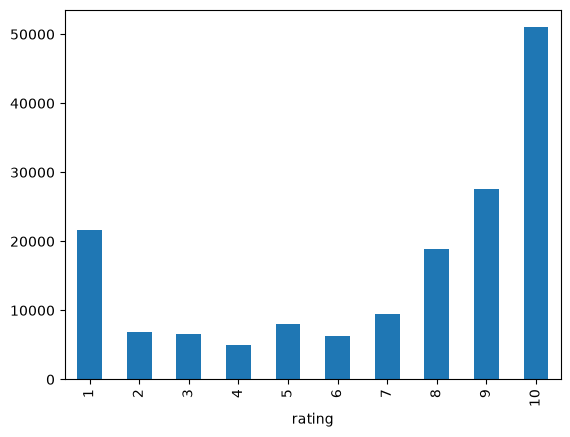

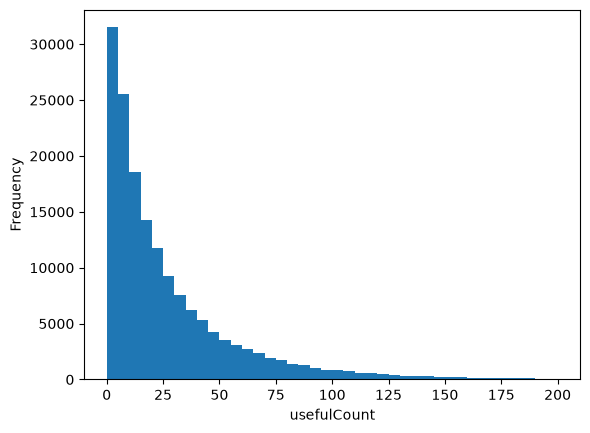

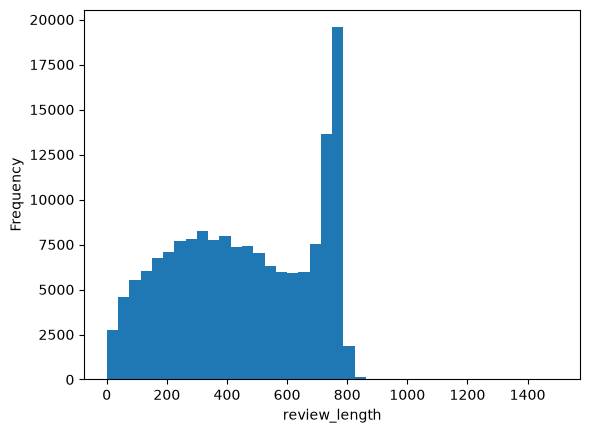

In [5]:
EDA_df.distribution_inspect()

In [6]:
EDA_df.correlation()

Data Field Correlation
+------------------+--------------------+-------------------+
|rating_usefulCount|         rating_date|   usefulCount_date|
+------------------+--------------------+-------------------+
|0.2341853750636649|-0.19623579544730904|-0.2690699925232411|
+------------------+--------------------+-------------------+



### Data Cleaning
A crucial step in the data preprocessing pipeline, aimed at improving the quality and accuracy of the dataset before analysis.
- Identifying Missing Values
- Handling Outliers
- Correcting Invalid Entries
- Removing Duplicates
- Standardizing Data: Ensure consistency in data representation.
- Transforming Variables: Apply necessary transformations to variables to enhance their interpretability or suitability for analysis.

In [7]:
def data_cleaning(df: DataFrame) -> DataFrame:
    import json
    with open("replacement.json","r",encoding="utf-8") as f:
        replacement = json.load(f)

    def replace_condition_and_review(df: DataFrame) -> DataFrame:
        pairs = []
        for old, new in replacement["condition"].items():
            pairs.extend((F.lit(old), F.lit(new)))
        condition_map = F.create_map(*pairs)
        df = df.withColumn(
            "condition",
            F.coalesce(condition_map[F.col("condition")], F.col("condition")),
        )

        review = F.col("review")
        for old, new in replacement["html_entities"].items():
            review = F.regexp_replace(review, old, new)
        return df.withColumn("review", review)
    
    row_count = df.count()
    df = df.dropna(subset="condition")
    print(f"After dropping rows with a null `condition`\nRow count: {row_count} -> {df.count()}, removed {row_count - df.count()} rows")
    row_count = df.count()

    df = df.filter(~F.col("condition").contains("</span> users found this comment helpful"))
    print(f"After dropping rows whose `condition` contains '</span> users found this comment helpful'\nRow count: {row_count} -> {df.count()}, removed {row_count - df.count()} rows")
    
    # There are truncated `condition` values (inspired by LLM), and `review` contains HTML entities
    remaining_conditions = df.filter(F.col("condition").isin(list(replacement["condition"]))).count()
    remaining_entities = df.filter(F.col("review").rlike("&(#\\d+|[A-Za-z]+);")).count()
    print(f"Before replacement: {remaining_conditions} truncated `condition` values, {remaining_entities} `review` values contain HTML entities")
    df = replace_condition_and_review(df)
    remaining_conditions = df.filter(F.col("condition").isin(list(replacement["condition"]))).count()
    remaining_entities = df.filter(F.col("review").rlike("&(#\\d+|[A-Za-z]+);")).count()
    print(f"After replacement: {remaining_conditions} truncated `condition` values, {remaining_entities} `review` values contain HTML entities")
    

    df = df.withColumn(
        "review",
        F.regexp_replace(F.trim(F.regexp_replace("review",r'^"|"$',"")),r"\s+"," ")
    )

    # For duplicate `review` values, keep only the row with the highest `usefulCount`.
    row_count = df.count()
    df_best = df.groupBy("review").agg(F.max("usefulCount").alias("usefulCount"))
    df = df.join(df_best, ["review", "usefulCount"]).dropDuplicates(["review"]).select(*df.columns)
    print(f"After keeping the row with the highest `usefulCount` for each `review`\nRow count: {row_count} -> {df.count()}, removed {row_count - df.count()} rows")

    df = df.withColumn(
        "usefulCount_log",
        F.log1p("usefulCount")
    )
    print("Added `usefulCount_log` = log(1 + `usefulCount`)")
    
    useful_stats = df.agg(
        F.lit("usefulCount").alias("column"),
        F.variance("usefulCount").alias("variance"),
        F.stddev("usefulCount").alias("stddev"),
        F.skewness("usefulCount").alias("skewness"),
    )
    useful_log_stats = df.agg(
        F.lit("usefulCount_log").alias("column"),
        F.variance("usefulCount_log").alias("variance"),
        F.stddev("usefulCount_log").alias("stddev"),
        F.skewness("usefulCount_log").alias("skewness"),
    )
    useful_stats.union(useful_log_stats).show()

    print("Added `days` = days since 1970-01-01 from `date`")
    df = df.withColumn(
        "days",
        F.unix_date("date")
    )
    df.collect()
    return df

In [8]:
if REBUILD_CLEANING:
    print("Before data cleaning:")
    df_raw.show(10,truncate=80)
    df_cleaned = data_cleaning(df_raw).cache()
    df_cleaned.write.mode("overwrite").parquet("df_cleaned.parquet")
    print("After data cleaning:")
    df_cleaned.show(10,truncate=80)
else:
    try:
        df_cleaned = ss.read.parquet("df_cleaned.parquet").cache()
        print("Load the cleaned dataset")
    except:
        print("Load Error, Please restart the notebook.")


Load the cleaned dataset


After data cleaning:
DataFrame overview
+--------+--------------------------------------------------+-----------------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+-----+
|uniqueID|                                          drugName|              condition|                                                                          review|rating|      date|usefulCount|   usefulCount_log| days|
+--------+--------------------------------------------------+-----------------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+-----+
|   20474|                                             Afrin|       Nasal Congestion| Afrin is great and it works in seconds. Just don't use it more than 3 days i...|    10|2017-06-21|          1|0.6931471805599453|17338|
|   50989|                                      Azithromycin|    Chlamyd

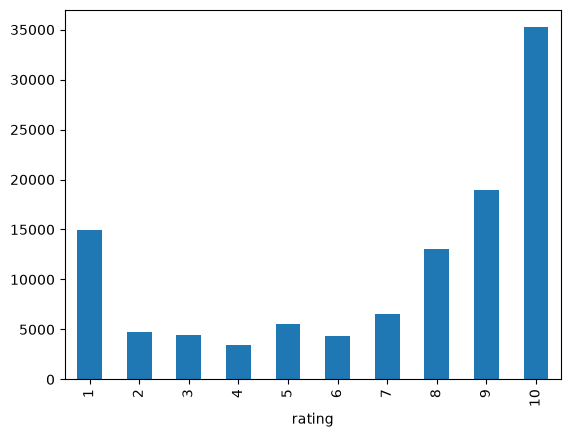

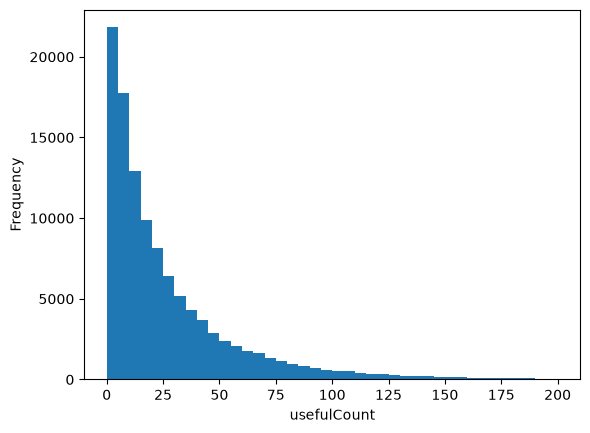

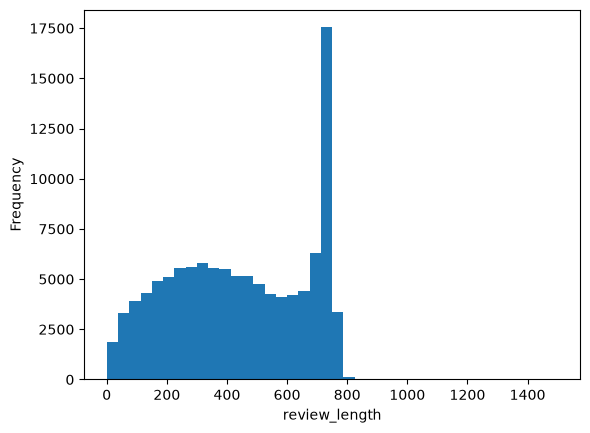

In [9]:
print("After data cleaning:")
EDA_df_cleaned = EDA(df_cleaned)
EDA_df_cleaned.dataframe_overview()
EDA_df_cleaned.granularity()
EDA_df_cleaned.distribution_inspect()
EDA_df_cleaned.correlation()

In [10]:
from pyexpat import model
from pyspark.ml.feature import CountVectorizer, Tokenizer, IDF, StringIndexer, VectorAssembler, OneHotEncoder
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression

class EmbeddingModel:
    @staticmethod
    def TFIDF() -> list:
        cv = CountVectorizer(inputCol="words",outputCol="tf",vocabSize=5000,minDF=5)
        idf = IDF(inputCol="tf",outputCol="tfidf")
        condition_idx = StringIndexer(
            inputCol="condition",
            outputCol="condition_idx",
            handleInvalid="keep"
        )
        condition_vec = OneHotEncoder(
            inputCol = "condition_idx",
            outputCol= "condition_vec",
            handleInvalid="keep"
        )
        drugName_idx = StringIndexer(
            inputCol="drugName",
            outputCol="drugName_idx",
            handleInvalid = "keep"
        )
        assembler = VectorAssembler(
            inputCols = ["tfidf","condition_vec","drugName_idx","days","usefulCount_log"],
            outputCol="features"
        )
        return [cv,idf,condition_idx,condition_vec,drugName_idx,assembler]
        

In [11]:
class AnalyticsModel:
    @staticmethod
    def linear_regression():
        return LogisticRegression(featuresCol="features",labelCol="rating")



In [ ]:
def model_combine(embedding, analytics) -> Pipeline:
    tokenizer = Tokenizer(inputCol="review",outputCol="words")
    return Pipeline(stages = [tokenizer,*embedding,analytics])

df_train,df_test = df_cleaned.randomSplit([0.8,0.1],seed = SEED)
tfidf_regression_pipeline = model_combine(
    EmbeddingModel.TFIDF(),
    AnalyticsModel.linear_regression()
)
tfidf_regression_model = tfidf_regression_pipeline.fit(df_train)
pred = tfidf_regression_model.transform(df_test)

26/10/27 11:08:17 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


In [ ]:
pred.select(
    "uniqueID",
    "rating",
    "prediction"
).show()

+--------+------+----------+
|uniqueID|rating|prediction|
+--------+------+----------+
|     156|     7|       5.0|
|     220|     1|       1.0|
|     450|     8|       9.0|
|     695|     4|       7.0|
|     705|     3|       1.0|
|     815|    10|      10.0|
|    1133|     7|       9.0|
|    1316|     9|       1.0|
|    1633|    10|      10.0|
|    1637|    10|       9.0|
|    1719|     1|       5.0|
|    2120|    10|      10.0|
|    2193|    10|      10.0|
|    2301|     6|       1.0|
|    2356|     8|      10.0|
|    2563|     2|       1.0|
|    2692|     1|       4.0|
|    2739|    10|       9.0|
|    2938|    10|      10.0|
|    3156|     1|       1.0|
+--------+------+----------+
only showing top 20 rows


26/10/27 00:40:59 WARN DAGScheduler: Broadcasting large task binary with size 1233.0 KiB


In [ ]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, RegressionEvaluator

class Scorer:
    def __init__(self) -> None:
        schema = StructType(
            [
                StructField("model",StringType(),False),
                StructField("metric",StringType(),False),
                StructField("value",DoubleType(),False)
            ]
        )
        self.df = ss.createdDataFrame([],schema)

pred = pred.cache()
pred.count()

def classification_score(metric):
    return MulticlassClassificationEvaluator(
        labelCol="rating",
        predictionCol="prediction",
        metricName=metric,
    ).evaluate(pred)

def regression_score(metric):
    return RegressionEvaluator(
        labelCol="rating",
        predictionCol="prediction",
        metricName=metric,
    ).evaluate(pred)

print("accuracy", classification_score("accuracy"))
print("weighted F1", classification_score("f1"))
print("MAE", regression_score("mae"))
print("RMSE", regression_score("rmse"))

26/10/27 00:40:59 WARN DAGScheduler: Broadcasting large task binary with size 1292.0 KiB
26/10/27 00:41:00 WARN DAGScheduler: Broadcasting large task binary with size 1298.4 KiB
26/10/27 00:41:00 WARN DAGScheduler: Broadcasting large task binary with size 1308.1 KiB
26/10/27 00:41:00 WARN DAGScheduler: Broadcasting large task binary with size 1308.1 KiB


accuracy 0.3870496592015579
weighted F1 0.361769544452631
MAE 1.7342583576760793
RMSE 2.8613559723755344


26/10/27 00:41:00 WARN DAGScheduler: Broadcasting large task binary with size 1308.2 KiB
26/10/27 00:41:00 WARN DAGScheduler: Broadcasting large task binary with size 1310.9 KiB
26/10/27 00:41:00 WARN DAGScheduler: Broadcasting large task binary with size 1311.7 KiB
26/10/27 00:41:00 WARN DAGScheduler: Broadcasting large task binary with size 1308.2 KiB
26/10/27 00:41:00 WARN DAGScheduler: Broadcasting large task binary with size 1310.9 KiB
26/10/27 00:41:00 WARN DAGScheduler: Broadcasting large task binary with size 1311.7 KiB


26/10/27 00:49:42 WARN HeartbeatReceiver: Removing executor driver with no recent heartbeats: 128110 ms exceeds timeout 120000 ms
26/10/27 00:49:42 WARN SparkContext: Killing executors is not supported by current scheduler.
26/10/27 00:49:43 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:70)
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:44)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:359)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:34)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:132)
	at org.apache.spark.stora